Membaca dataset...

--- Proses Data Cleaning ---
[Prestasi] Dihapus 7 baris duplikat.
Pembersihan data selesai.

--- Mulai Exploratory Data Analysis (EDA) ---


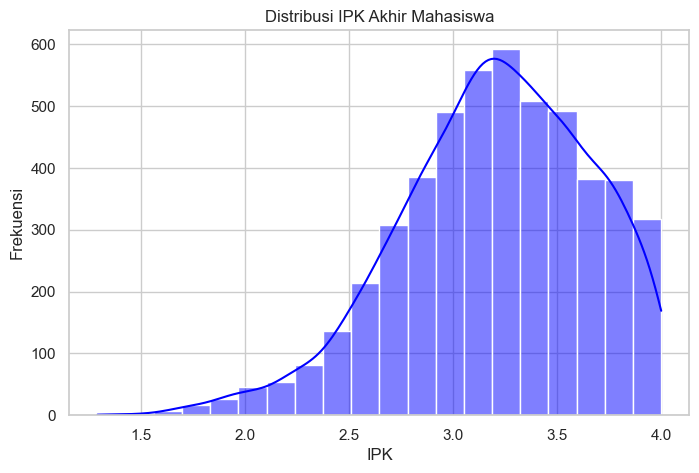

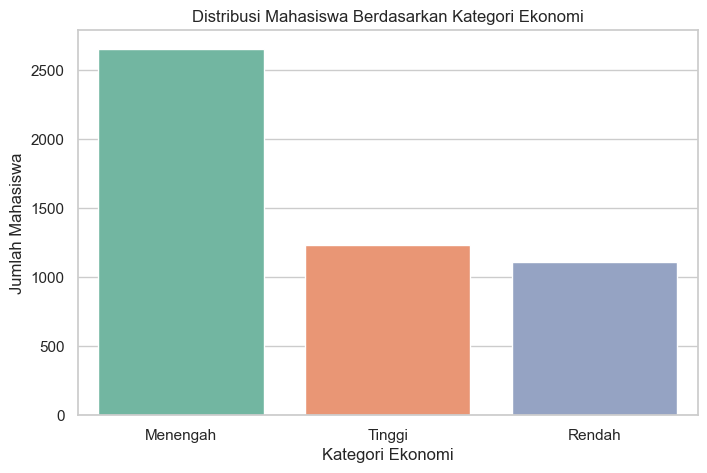

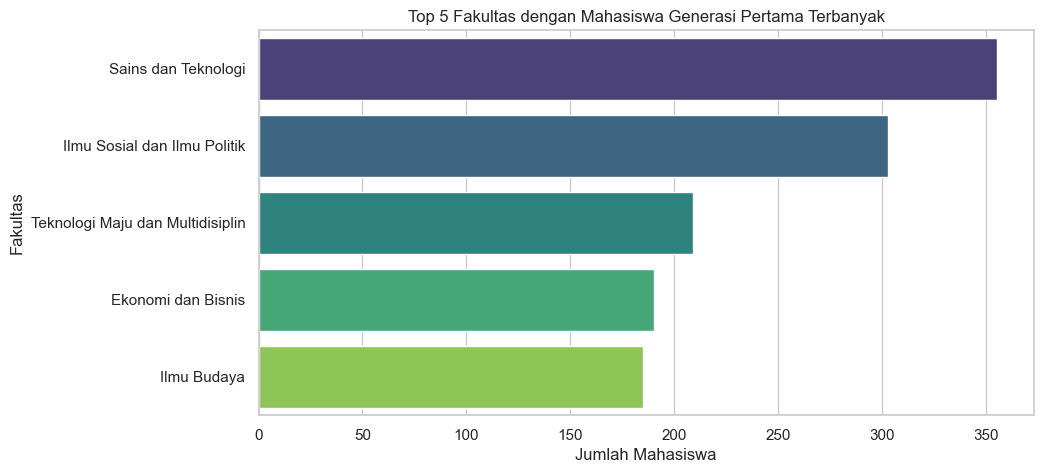

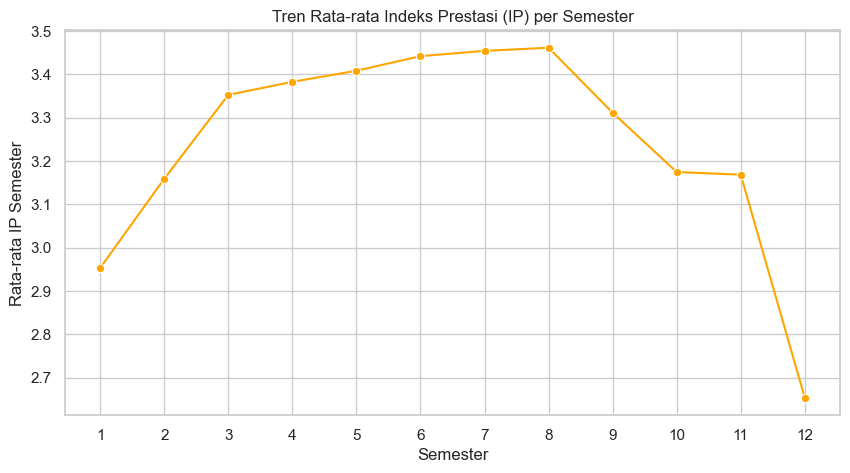

--- Ringkasan Master Dataset (Gabungan) ---
Total Baris & Kolom: (5000, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ID_Mahasiswa                    5000 non-null   object 
 1   Jenis_Kelamin                   5000 non-null   object 
 2   Usia                            5000 non-null   int64  
 3   Provinsi_Asal                   5000 non-null   object 
 4   Fakultas                        5000 non-null   object 
 5   Program_Studi                   5000 non-null   object 
 6   Angkatan                        5000 non-null   int64  
 7   Sumber_Pembiayaan_x             5000 non-null   object 
 8   Status_Mahasiswa                5000 non-null   object 
 9   IPK_Mahasiswa                   5000 non-null   float64
 10  Masa_Studi_Semester             5000 non-null   int64  
 11  Tempat_Tinggal     

,ID_Mahasiswa,Jenis_Kelamin,Usia,Provinsi_Asal,Fakultas,Program_Studi,Angkatan,Sumber_Pembiayaan_x,Status_Mahasiswa,IPK_Mahasiswa,...,Jumlah_Tanggungan_Keluarga,Sumber_Pembiayaan_y,Status_Penerima_Beasiswa,Jenis_Beasiswa,Kategori_UKT,Kepemilikan_Rumah,Bekerja_Sambil_Kuliah,Total_Prestasi,Rata_rata_IP_Semester,Semester_Terakhir
0,MHS00001,Perempuan,22,Jawa Timur,Farmasi,Farmasi,2023,Kerja Sendiri (part-time),Cuti,3.74,...,2,Kerja Sendiri (part-time),Tidak,Tidak Ada,3,Milik Sendiri,Tidak,3.0,3.740000,6
1,MHS00002,Laki-laki,22,Jawa Tengah,Ilmu Budaya,Ilmu Sejarah,2022,Orang Tua,Lulus,3.40,...,6,Orang Tua,Tidak,Tidak Ada,3,Sewa,Tidak,1.0,3.403750,8
2,MHS00003,Perempuan,19,Jawa Timur,Sains dan Teknologi,Statistika,2025,Pinjaman/Kredit Pendidikan,Aktif,2.71,...,7,Pinjaman/Kredit Pendidikan,Tidak,Tidak Ada,1,Sewa,Ya,1.0,2.715000,2
3,MHS00004,Laki-laki,23,Jawa Timur,Kesehatan Masyarakat,Gizi,2022,Orang Tua,Lulus,2.99,...,4,Orang Tua,Tidak,Tidak Ada,4,Milik Sendiri,Tidak,1.0,2.990000,8
4,MHS00005,Laki-laki,22,Jawa Timur,FIKKIA Banyuwangi,Akuakultur (FIKKIA Banyuwangi),2024,Kerja Sendiri (part-time),Aktif,3.47,...,5,Kerja Sendiri (part-time),Tidak,Tidak Ada,1,Menumpang,Tidak,0.0,3.467500,4
5,MHS00006,Perempuan,21,Nusa Tenggara Timur,Perikanan dan Kelautan,Akuakultur,2024,Orang Tua,Aktif,3.24,...,2,Orang Tua,Tidak,Tidak Ada,4,Sewa,Tidak,2.0,3.242500,4
6,MHS00007,Laki-laki,22,Kalimantan Selatan,FIKKIA Banyuwangi,Kesehatan Masyarakat (FIKKIA Banyuwangi),2025,Beasiswa,Aktif,2.89,...,3,Beasiswa,Ya,KIP-Kuliah,2,Sewa,Tidak,1.0,2.890000,2
7,MHS00008,Perempuan,23,Jawa Timur,Sains dan Teknologi,Kimia,2022,Orang Tua,Lulus,3.35,...,1,Orang Tua,Tidak,Tidak Ada,7,Milik Sendiri,Tidak,3.0,3.350000,8
8,MHS00009,Laki-laki,21,Jawa Barat,FIKKIA Banyuwangi,Kesehatan Masyarakat (FIKKIA Banyuwangi),2023,Orang Tua,Aktif,3.53,...,4,Orang Tua,Tidak,Tidak Ada,4,Milik Sendiri,Tidak,3.0,3.531667,6
9,MHS00010,Laki-laki,24,Jawa Timur,Sains dan Teknologi,Biologi,2021,Beasiswa,Lulus,2.77,...,6,Beasiswa,Ya,KIP-Kuliah,1,Milik Sendiri,Tidak,0.0,2.771250,8


In [1]:
from pathlib import Path
_candidates = [p / "02_Analisis" / "data" for p in [Path.cwd(), *Path.cwd().parents]] + [p / "data" for p in [Path.cwd(), *Path.cwd().parents]] + [Path.cwd(), *Path.cwd().parents]
DATA_DIR = next(p for p in _candidates if (p / "1_profil_mahasiswa_umum.csv").is_file())
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set style untuk visualisasi
sns.set_theme(style="whitegrid")
print("Membaca dataset...")
df_profil = pd.read_csv(DATA_DIR / "1_profil_mahasiswa_umum.csv", sep=";")
df_prestasi = pd.read_csv(DATA_DIR / "2_prestasi_mahasiswa.csv", sep=";")
df_gen1 = pd.read_csv(DATA_DIR / "3_generasi_pertama_kuliah.csv", sep=";")
df_ekonomi = pd.read_csv(DATA_DIR / "4_status_sosial_ekonomi.csv", sep=";")
df_ipk = pd.read_csv(DATA_DIR / "5_riwayat_ipk_semester.csv", sep=";")

datasets = {
    "Profil Umum": df_profil,
    "Prestasi": df_prestasi,
    "Generasi Pertama": df_gen1,
    "Status Ekonomi": df_ekonomi,
    "Riwayat IPK": df_ipk
}

# ==========================================
# 2. PEMERIKSAAN & PEMBERSIHAN DATA (CLEANING)
# ==========================================
print("\n--- Proses Data Cleaning ---")

for name, df in datasets.items():
    # Cek duplikat
    duplicates = df.duplicated().sum()
    if duplicates > 0:
        df.drop_duplicates(inplace=True)
        print(f"[{name}] Dihapus {duplicates} baris duplikat.")
    
    # Cek Missing Values
    missing_values = df.isnull().sum().sum()
    if missing_values > 0:
        print(f"[{name}] Terdapat {missing_values} missing values. Mengisi dengan nilai default...")
        # Mengisi data numerik dengan median, dan kategorikal dengan modus
        for col in df.columns:
            if df[col].dtype == 'object':
                df[col].fillna(df[col].mode()[0], inplace=True)
            else:
                df[col].fillna(df[col].median(), inplace=True)
    
    # Menghapus spasi ekstra pada data string/kategorikal
    for col in df.select_dtypes(include=['object']).columns:
        df[col] = df[col].astype(str).str.strip()

print("Pembersihan data selesai.\n")

# ==========================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
print("--- Mulai Exploratory Data Analysis (EDA) ---")
# a. Distribusi IPK Mahasiswa (Dari Dataset Profil)
plt.figure(figsize=(8, 5))
sns.histplot(df_profil['IPK_Mahasiswa'], bins=20, kde=True, color='blue')
plt.title('Distribusi IPK Akhir Mahasiswa')
plt.xlabel('IPK')
plt.ylabel('Frekuensi')
plt.show()
# b. Distribusi Kategori Ekonomi
plt.figure(figsize=(8, 5))
sns.countplot(data=df_ekonomi, x='Kategori_Ekonomi', palette='Set2', 
              order=df_ekonomi['Kategori_Ekonomi'].value_counts().index)
plt.title('Distribusi Mahasiswa Berdasarkan Kategori Ekonomi')
plt.xlabel('Kategori Ekonomi')
plt.ylabel('Jumlah Mahasiswa')
plt.show()
# c. Top 5 Fakultas dengan Mahasiswa Generasi Pertama Terbanyak
# Menggabungkan data Profil dan Generasi Pertama
df_merged_gen1 = pd.merge(df_profil, df_gen1, on="ID_Mahasiswa", how="inner")
gen1_yes = df_merged_gen1[df_merged_gen1['Status_Generasi_Pertama'] == 'Ya']
plt.figure(figsize=(10, 5))
sns.countplot(data=gen1_yes, y='Fakultas', palette='viridis', 
              order=gen1_yes['Fakultas'].value_counts().iloc[:5].index)
plt.title('Top 5 Fakultas dengan Mahasiswa Generasi Pertama Terbanyak')
plt.xlabel('Jumlah Mahasiswa')
plt.ylabel('Fakultas')
plt.show()
# d. Tren Rata-rata IPK per Semester
plt.figure(figsize=(10, 5))
sns.lineplot(data=df_ipk, x='Semester_Ke', y='IP_Semester', marker='o', color='orange', errorbar=None)
plt.title('Tren Rata-rata Indeks Prestasi (IP) per Semester')
plt.xlabel('Semester')
plt.ylabel('Rata-rata IP Semester')
plt.xticks(np.arange(1, df_ipk['Semester_Ke'].max() + 1, 1))
plt.show()

# ==========================================
# 4. PENGGABUNGAN DATA (MERGING)
# ==========================================
df_prestasi_agg = df_prestasi.groupby('ID_Mahasiswa').agg(
    Total_Prestasi=('Jenis_Prestasi', 'count')
).reset_index()
# Agregasi Data Riwayat IPK: Mengambil nilai IP terakhir / rata-rata
df_ipk_agg = df_ipk.groupby('ID_Mahasiswa').agg(
    Rata_rata_IP_Semester=('IP_Semester', 'mean'),
    Semester_Terakhir=('Semester_Ke', 'max')
).reset_index()
# Merge semua tabel master
master_df = df_profil.copy()
master_df = pd.merge(master_df, df_gen1, on='ID_Mahasiswa', how='left')
master_df = pd.merge(master_df, df_ekonomi, on='ID_Mahasiswa', how='left')
master_df = pd.merge(master_df, df_prestasi_agg, on='ID_Mahasiswa', how='left')
master_df = pd.merge(master_df, df_ipk_agg, on='ID_Mahasiswa', how='left')
# Mahasiswa yang tidak punya prestasi diisi dengan 0
master_df['Total_Prestasi'].fillna(0, inplace=True)

print("--- Ringkasan Master Dataset (Gabungan) ---")
print(f"Total Baris & Kolom: {master_df.shape}")
print(master_df.info())
print("\nSampel Data Master:")
display(master_df.head(10))